In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio3_matrices_omp.csv').sort_values(['N', 'threads'])
df.pivot(index='threads', columns='N', values='speedup')

N,256,512,1024,2048
threads,,,,
1,1.0000,1.0000,1.0000,1.0000
2,1.7039,1.9659,1.7251,1.8576
4,1.9272,2.5851,3.0502,3.8045
8,2.3059,4.4061,4.1640,6.3891
16,0.3511,3.4861,4.4808,6.9925


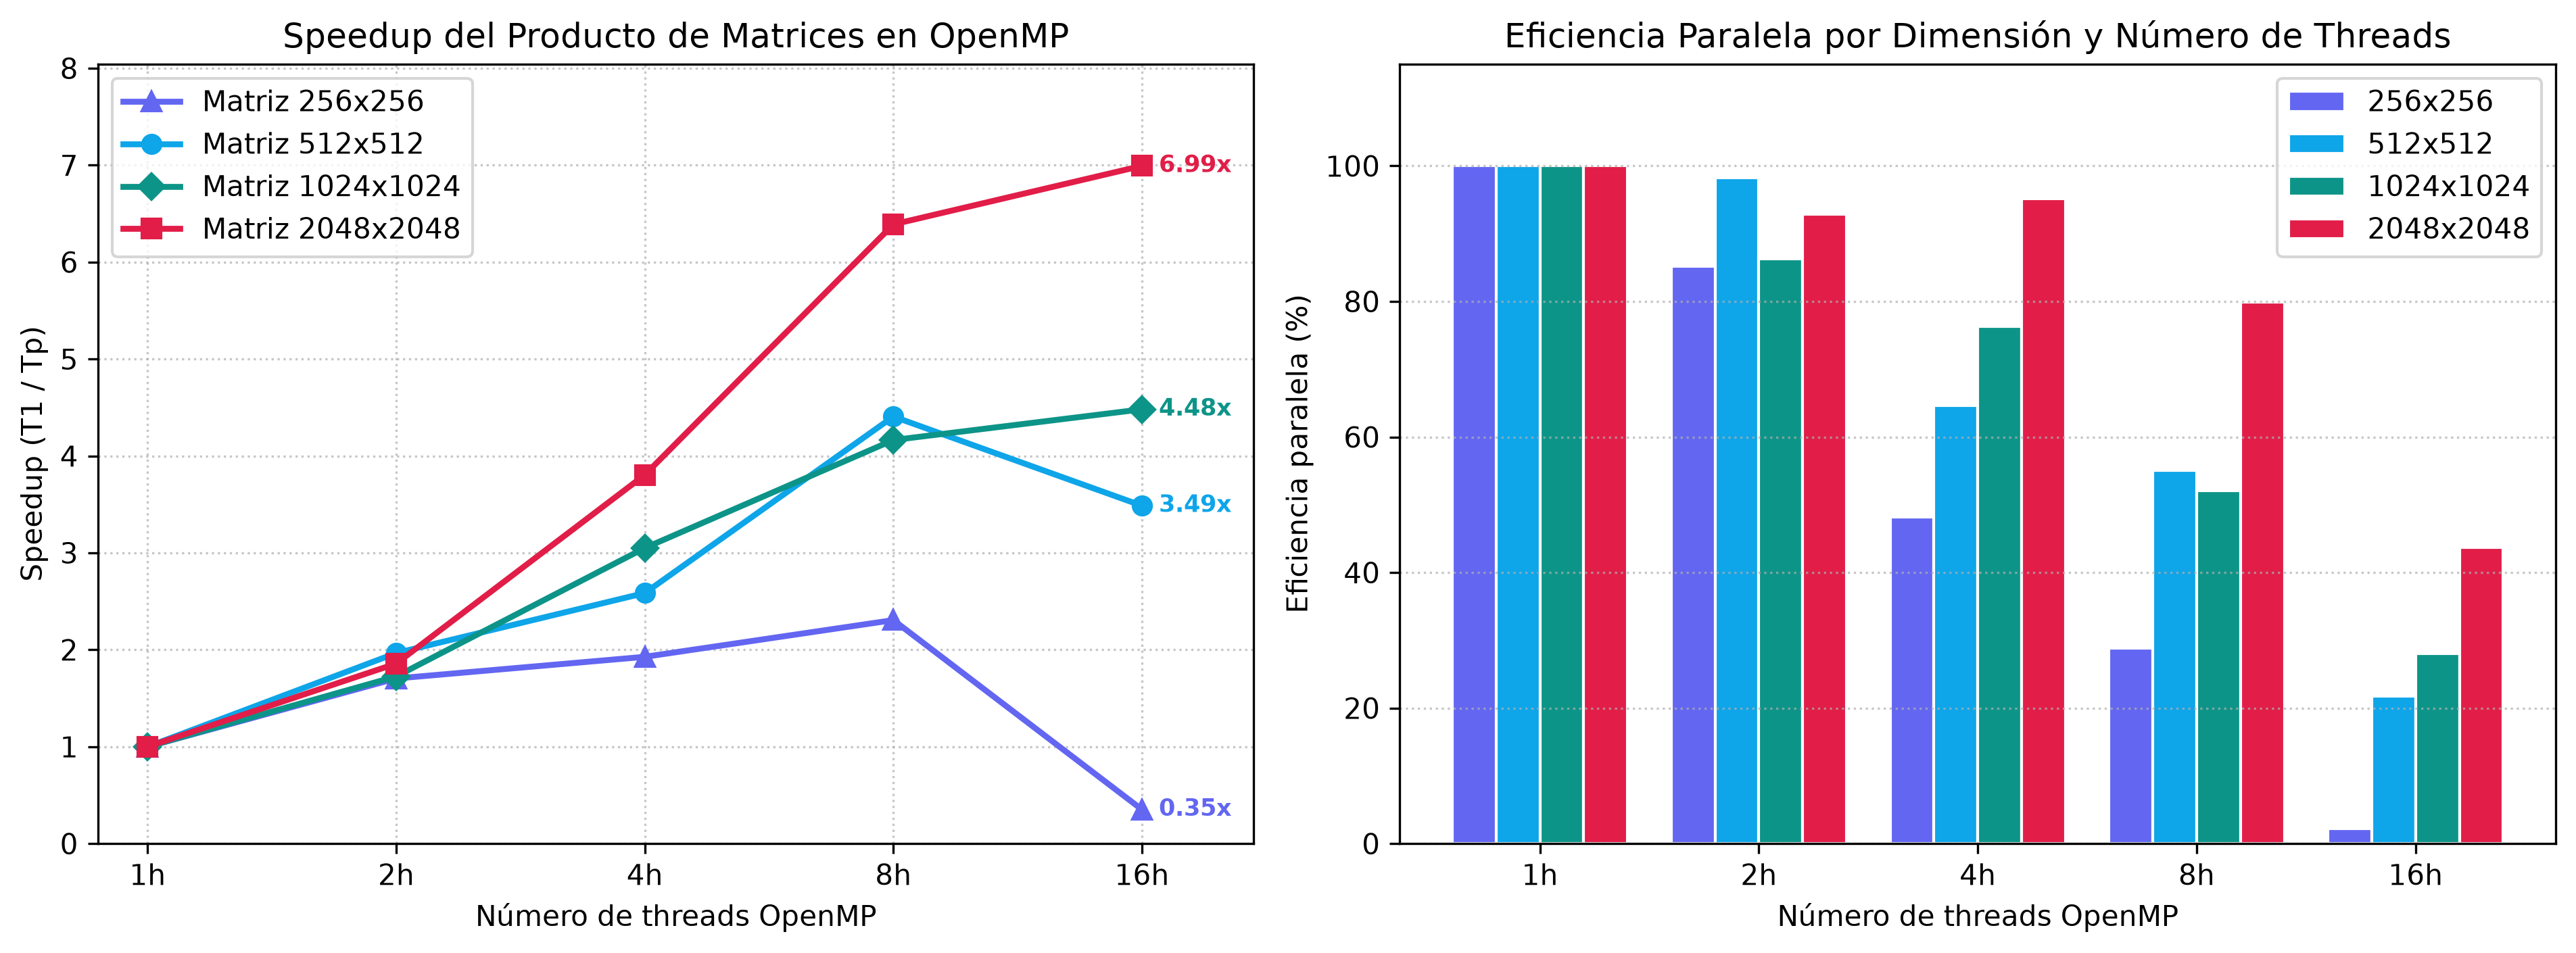

In [3]:
hilos = sorted(df['threads'].unique())
etiquetas_h = [f'{t}h' for t in hilos]
x = np.arange(len(hilos))

dimensiones = sorted(df['N'].unique())
colores = {256: '#6366f1', 512: '#0ea5e9', 1024: '#0d9488', 2048: '#e11d48'}
marcadores = {256: '^', 512: 'o', 1024: 'D', 2048: 's'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8), dpi=300)

# Panel izquierdo: Speedup por tamaño de matriz y número de threads
for N in dimensiones:
    sub = df[df['N'] == N].sort_values('threads')
    sp = sub['speedup'].to_numpy()
    ax1.plot(x, sp, marker=marcadores[N], markersize=6.5, linewidth=2.1, color=colores[N], label=f'Matriz {N}x{N}')
    ax1.annotate(f'{sp[-1]:.2f}x', (x[-1], sp[-1]), xytext=(6, 0), textcoords='offset points',
                 va='center', fontsize=8.5, color=colores[N], fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas_h)
ax1.set_xlim(-0.2, len(hilos) - 0.55)
ax1.set_ylim(0, max(df['speedup']) * 1.15)
ax1.set_xlabel('Número de threads OpenMP')
ax1.set_ylabel('Speedup (T1 / Tp)')
ax1.set_title('Speedup del Producto de Matrices en OpenMP')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.7)

# Panel derecho: Barras agrupadas de Eficiencia (%)
ancho = 0.20
desp = {256: -1.5 * ancho, 512: -0.5 * ancho, 1024: 0.5 * ancho, 2048: 1.5 * ancho}

for N in dimensiones:
    sub = df[df['N'] == N].sort_values('threads')
    ef = sub['eficiencia_pct'].to_numpy()
    ax2.bar(x + desp[N], ef, width=ancho, color=colores[N], edgecolor='white', label=f'{N}x{N}')

ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas_h)
ax2.set_ylim(0, 115)
ax2.set_xlabel('Número de threads OpenMP')
ax2.set_ylabel('Eficiencia paralela (%)')
ax2.set_title('Eficiencia Paralela por Dimensión y Número de Threads')
ax2.legend(loc='upper right')
ax2.grid(True, axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e3_matrices_omp.png', dpi=300)
plt.show()